In [ ]:
import pandas as pd
import scipy.stats as sc
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

oczekiwana 0


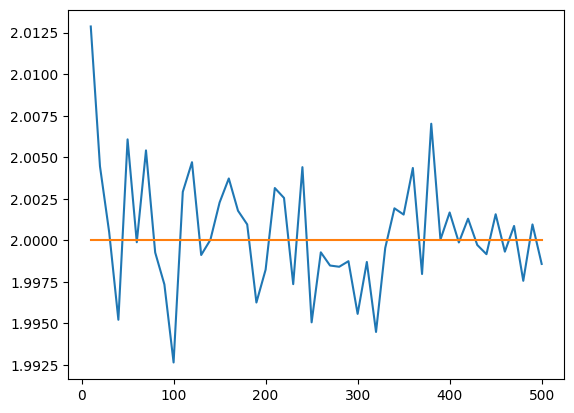

wariancja 0


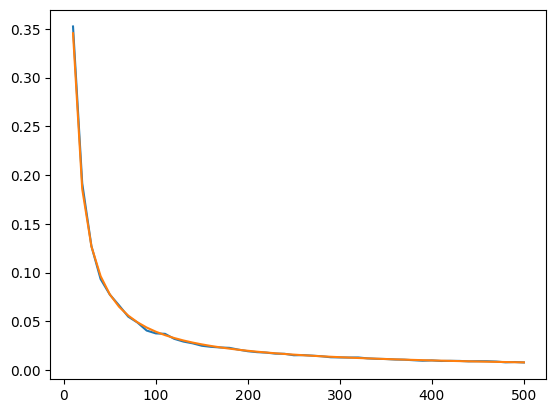

MSE 0


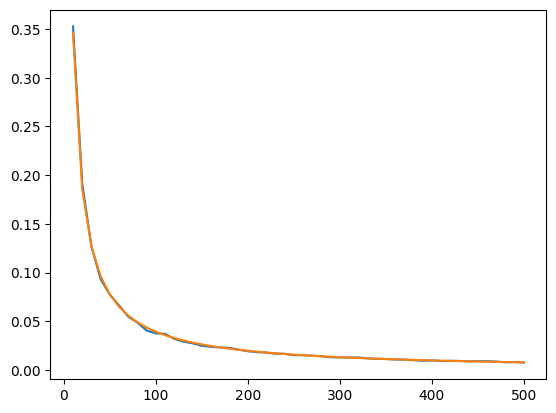

bias 0


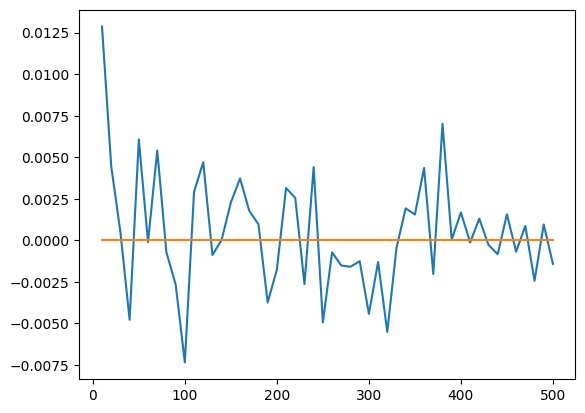

oczekiwana 1


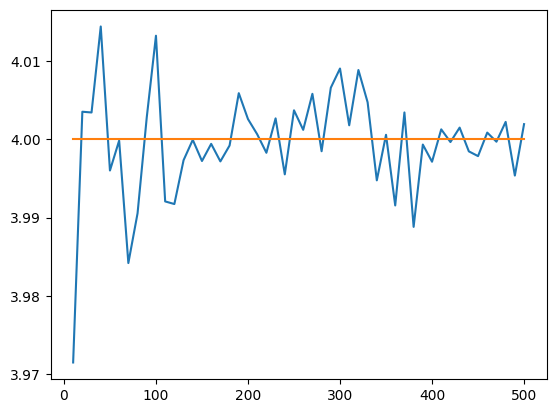

wariancja 1


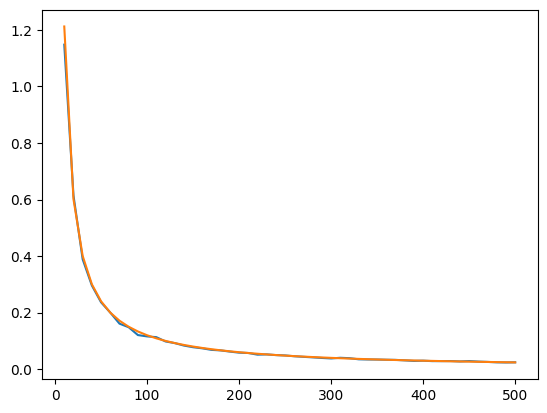

MSE 1


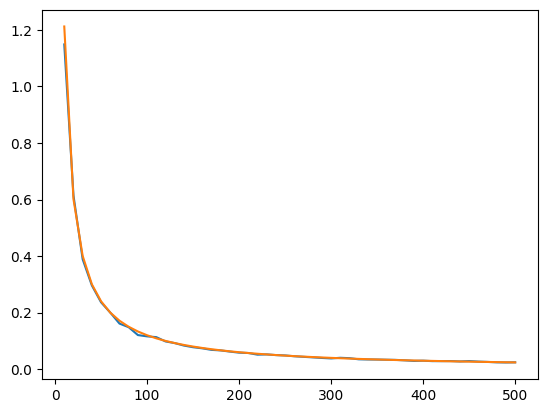

bias 1


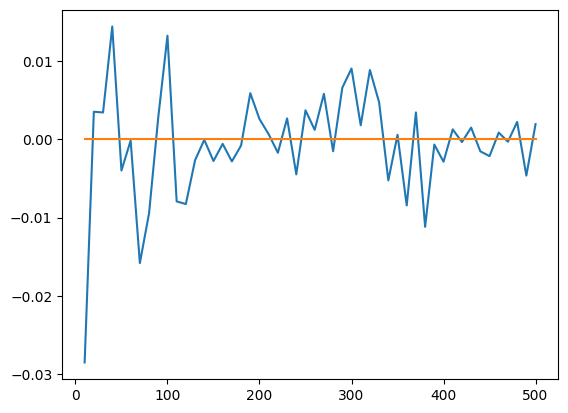

In [ ]:
#1
def estymatory_MNK_wspolczynnikow(kolumna_x,kolumna_y):
    y_srednie = np.mean(kolumna_y)
    x_srednie = np.mean(kolumna_x)
    y_odjac_srednie = kolumna_y - y_srednie
    x_odjac_srednie = kolumna_x - x_srednie
    x_odjac_srednie_kwadrat = x_odjac_srednie ** 2
    x_razy_y_odjac_srednie = x_odjac_srednie * y_odjac_srednie

    b_1 = np.sum(x_razy_y_odjac_srednie) / np.sum(x_odjac_srednie_kwadrat)
    b_0 = y_srednie - b_1 * x_srednie

    return b_0,b_1

def xi(n):
    wektor = np.arange(n)/n
    return wektor

def eps(n):
    return np.random.normal(0,1,n)

def model_regresji(xi,eps):
    return 2 + 4 * xi + eps



def monte_carlo(n,m):
    wektor_estymatorow_b0 = []
    wektor_estymatorow_b1 = []

    wektor_x = xi(n)

    for _ in range(m):
        wektor_eps = eps(n)
        wektor_y = model_regresji(wektor_x,wektor_eps)

        b0_daszek, b1_daszek = estymatory_MNK_wspolczynnikow(wektor_x, wektor_y)

        wektor_estymatorow_b0.append(b0_daszek)
        wektor_estymatorow_b1.append(b1_daszek)

    wektor_estymatorow_b0 = np.array(wektor_estymatorow_b0)
    wektor_estymatorow_b1 = np.array(wektor_estymatorow_b1)

    oczekiwana_0 = np.mean(wektor_estymatorow_b0)
    oczekiwana_1 = np.mean(wektor_estymatorow_b1)

    wariancja_0 = np.var(wektor_estymatorow_b0)
    wariancja_1 = np.var(wektor_estymatorow_b1)

    MSE_0 = np.sum((wektor_estymatorow_b0 - 2) ** 2)/m
    MSE_1 = np.sum((wektor_estymatorow_b1 - 4) ** 2)/m

    bias_0 = oczekiwana_0 - 2
    bias_1 = oczekiwana_1 - 4



    teoretyczna_oczekiwana_0 = 2
    teoretyczna_oczekiwana_1 = 4

    suma_kwadratow = np.sum((np.mean(wektor_x) - wektor_x)**2)
    teoretyczna_wariancja_0 = 1/n + np.mean(wektor_x)**2/suma_kwadratow
    teoretyczna_wariancja_1 = 1/suma_kwadratow

    teoretyczne_MSE_0 = teoretyczna_wariancja_0.copy()
    teoretyczne_MSE_1 = teoretyczna_wariancja_1.copy()

    teoretyczny_bias_0 = 0
    teoretyczny_bias_1 = 0


    return  (
            (teoretyczna_oczekiwana_0,teoretyczna_wariancja_0,teoretyczne_MSE_0,teoretyczny_bias_0),
            (oczekiwana_0,wariancja_0,MSE_0,bias_0), 
            (teoretyczna_oczekiwana_1,teoretyczna_wariancja_1,teoretyczne_MSE_1,teoretyczny_bias_1),
            (oczekiwana_1,wariancja_1,MSE_1,bias_1)
            )


wektor_n = []

wektor_teoretyczna_oczekiwana_0 = []
wektor_oczekiwana_0 = []

wektor_teoretyczna_wariancja_0 = []
wektor_wariancja_0 = []

wektor_teoretyczna_MSE_0 = []
wektor_MSE_0 = []

wektor_teoretyczny_bias_0 = []
wektor_bias_0 = []

wektor_teoretyczna_oczekiwana_1 = []
wektor_oczekiwana_1 = []

wektor_teoretyczna_wariancja_1 = []
wektor_wariancja_1 = []

wektor_teoretyczna_MSE_1 = []
wektor_MSE_1 = []

wektor_teoretyczny_bias_1 = []
wektor_bias_1 = []


for i in range(1,51):
    n = i * 10

    wektor_n.append(n)

    teoretyczne_wlasnosci_0, empiryczne_wlasnosci_0, teoretyczne_wlasnosci_1, empiryczne_wlasnosci_1  = monte_carlo(n,2000)

    wektor_teoretyczna_oczekiwana_0.append(teoretyczne_wlasnosci_0[0])
    wektor_teoretyczna_wariancja_0.append(teoretyczne_wlasnosci_0[1])
    wektor_teoretyczna_MSE_0.append(teoretyczne_wlasnosci_0[2])
    wektor_teoretyczny_bias_0.append(teoretyczne_wlasnosci_0[3])

    wektor_oczekiwana_0.append(empiryczne_wlasnosci_0[0])
    wektor_wariancja_0.append(empiryczne_wlasnosci_0[1])
    wektor_MSE_0.append(empiryczne_wlasnosci_0[2])
    wektor_bias_0.append(empiryczne_wlasnosci_0[3])

    wektor_teoretyczna_oczekiwana_1.append(teoretyczne_wlasnosci_1[0])
    wektor_teoretyczna_wariancja_1.append(teoretyczne_wlasnosci_1[1])
    wektor_teoretyczna_MSE_1.append(teoretyczne_wlasnosci_1[2])
    wektor_teoretyczny_bias_1.append(teoretyczne_wlasnosci_1[3])
    
    wektor_oczekiwana_1.append(empiryczne_wlasnosci_1[0])
    wektor_wariancja_1.append(empiryczne_wlasnosci_1[1])
    wektor_MSE_1.append(empiryczne_wlasnosci_1[2])
    wektor_bias_1.append(empiryczne_wlasnosci_1[3])
    

print('oczekiwana 0')
plt.plot(wektor_n,wektor_oczekiwana_0)
plt.plot(wektor_n,wektor_teoretyczna_oczekiwana_0)
plt.show()

print('wariancja 0')
plt.plot(wektor_n,wektor_wariancja_0)
plt.plot(wektor_n,wektor_teoretyczna_wariancja_0)
plt.show()

print('MSE 0')
plt.plot(wektor_n,wektor_MSE_0)
plt.plot(wektor_n,wektor_teoretyczna_MSE_0)
plt.show()

print('bias 0')
plt.plot(wektor_n,wektor_bias_0)
plt.plot(wektor_n,wektor_teoretyczny_bias_0)
plt.show()



print('oczekiwana 1')
plt.plot(wektor_n,wektor_oczekiwana_1)
plt.plot(wektor_n,wektor_teoretyczna_oczekiwana_1)
plt.show()

print('wariancja 1')
plt.plot(wektor_n,wektor_wariancja_1)
plt.plot(wektor_n,wektor_teoretyczna_wariancja_1)
plt.show()

print('MSE 1')
plt.plot(wektor_n,wektor_MSE_1)
plt.plot(wektor_n,wektor_teoretyczna_MSE_1)
plt.show()

print('bias 1')
plt.plot(wektor_n,wektor_bias_1)
plt.plot(wektor_n,wektor_teoretyczny_bias_1)
plt.show()



DLA N = 100


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_13692\431320586.py:38: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([wektor_estymatorow_b0_norm, wektor_estymatorow_b0_t3,wektor_estymatorow_b0_t10], labels=['normalny', 'student3','student10'])


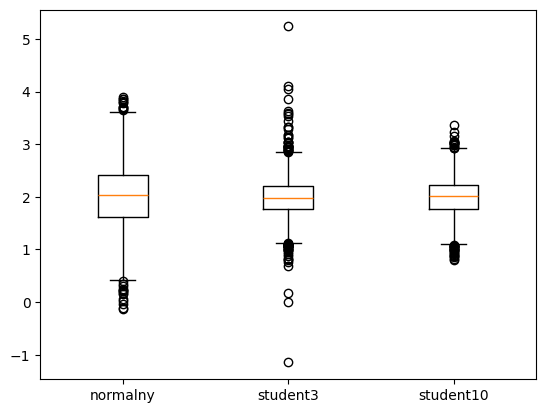

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_13692\431320586.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([wektor_estymatorow_b1_norm, wektor_estymatorow_b1_t3,wektor_estymatorow_b1_t10], labels=['normalny', 'student3','student10'])


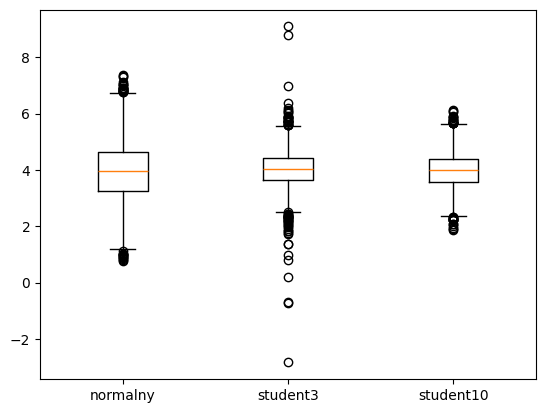

DLA N = 50


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_13692\431320586.py:38: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([wektor_estymatorow_b0_norm, wektor_estymatorow_b0_t3,wektor_estymatorow_b0_t10], labels=['normalny', 'student3','student10'])


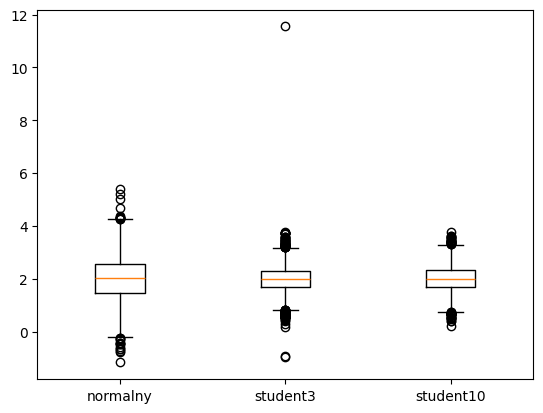

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_13692\431320586.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([wektor_estymatorow_b1_norm, wektor_estymatorow_b1_t3,wektor_estymatorow_b1_t10], labels=['normalny', 'student3','student10'])


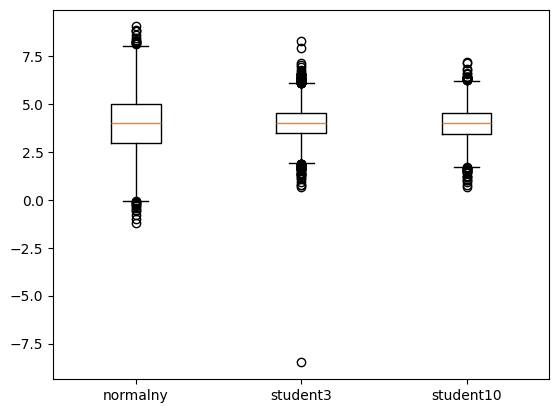

DLA N = 20


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_13692\431320586.py:38: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([wektor_estymatorow_b0_norm, wektor_estymatorow_b0_t3,wektor_estymatorow_b0_t10], labels=['normalny', 'student3','student10'])


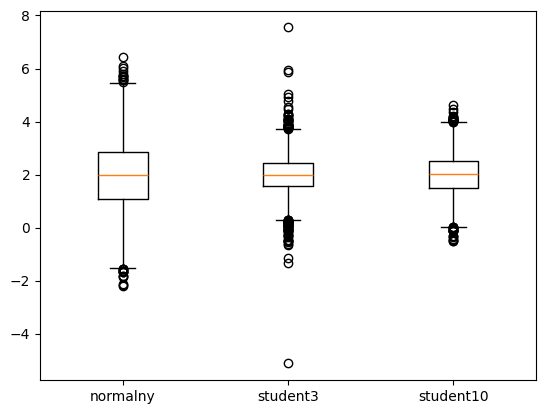

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_13692\431320586.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([wektor_estymatorow_b1_norm, wektor_estymatorow_b1_t3,wektor_estymatorow_b1_t10], labels=['normalny', 'student3','student10'])


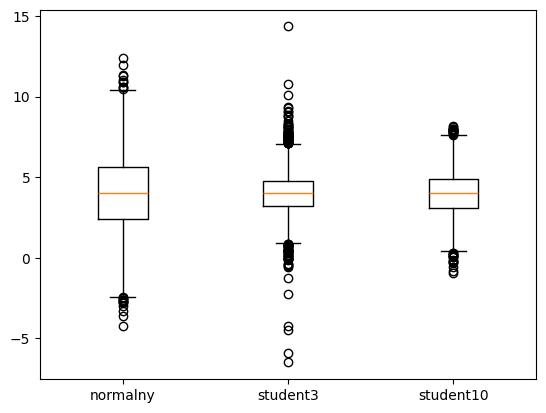

DLA N = 500


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_13692\431320586.py:38: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([wektor_estymatorow_b0_norm, wektor_estymatorow_b0_t3,wektor_estymatorow_b0_t10], labels=['normalny', 'student3','student10'])


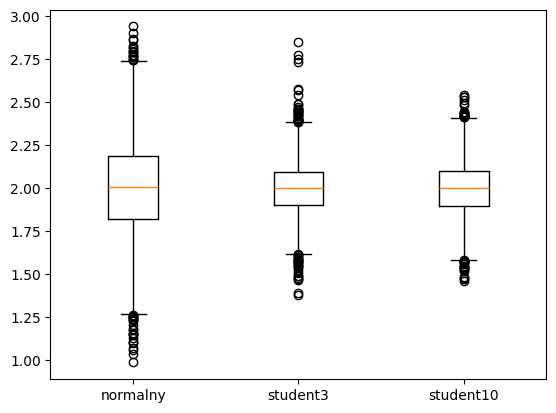

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_13692\431320586.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([wektor_estymatorow_b1_norm, wektor_estymatorow_b1_t3,wektor_estymatorow_b1_t10], labels=['normalny', 'student3','student10'])


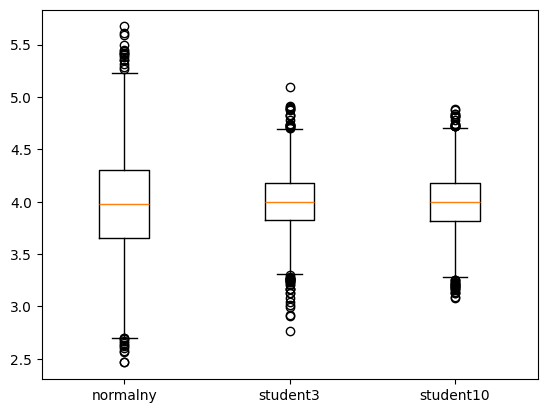

In [30]:
# zad 2

def model_regresji(xi,eps):
    return 2 + 4 * xi + eps

def eps_1(n):
    return np.random.normal(0,3,n)

def eps_2(n):
    return np.random.standard_t(3,n)

def eps_3(n):
    return np.sqrt(2.4) * np.random.standard_t(10,n)

def monte_carlo_2(n,m,funkcja_eps):
    wektor_estymatorow_b0 = []
    wektor_estymatorow_b1 = []

    wektor_x = xi(n)

    for _ in range(m):
        wektor_eps = funkcja_eps(n)
        wektor_y = model_regresji(wektor_x,wektor_eps)

        b0_daszek, b1_daszek = estymatory_MNK_wspolczynnikow(wektor_x, wektor_y)

        wektor_estymatorow_b0.append(b0_daszek)
        wektor_estymatorow_b1.append(b1_daszek)

    return wektor_estymatorow_b0, wektor_estymatorow_b1

for n in {20,50,100,500}:
    print(f'DLA N = {n}')
    wektor_estymatorow_b0_norm, wektor_estymatorow_b1_norm = monte_carlo_2(n,5000,eps_1)
    wektor_estymatorow_b0_t3, wektor_estymatorow_b1_t3 = monte_carlo_2(n,5000,eps_2)
    wektor_estymatorow_b0_t10, wektor_estymatorow_b1_t10 = monte_carlo_2(n,5000,eps_3)

    plt.boxplot([wektor_estymatorow_b0_norm, wektor_estymatorow_b0_t3,wektor_estymatorow_b0_t10], labels=['normalny', 'student3','student10'])
    plt.show()

    plt.boxplot([wektor_estymatorow_b1_norm, wektor_estymatorow_b1_t3,wektor_estymatorow_b1_t10], labels=['normalny', 'student3','student10'])
    plt.show()





